<img src='sharif.png' alt="SUT logo" width=200 height=200 align=left class="saturate" >


<br>
<font>
<div dir=ltr align=center>
<font color=0F5298 size=7>
    Machine Learning <br>
<font color=2565AE size=5>
    Electrical Engineering Department <br>
    spring 2026<br>
<font color=3C99D size=5>
    Practical Assignment 5 - Unsupervised Learning<br>
<font color=696880 size=4>
     Professor : Sajad Amini <br>
<font color=696880 size=5>
     designer : Mohammad Reza Monemian


Personal identification details have been omitted from this public portfolio copy.

In [1]:
#import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.cluster.hierarchy import fcluster

<font color=red size=3>
notice that you can not use sklearn.decomposition and sklearn.cluster libary in this home work! you should implement pca and kmeans from scratch.

## Overview
In this assignment, you will perform PCA and K-Means clustering on credit card customer data. dataset contains information about customer’s use of credit cards. The goal is to reduce the dataset’s dimensionality using PCA and then apply clustering to segment customers. You will compare the clustering performance both before and after PCA. Additionally, you'll be asked to explain the theory and decisions behind each step.

## Data Preprocessing (15 points)
Read the dataset.CSV file and display a few samples.

In [2]:
# todo

df = pd.read_csv('dataset.csv')
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


Display dataset information.

In [5]:
# todo

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

Which column do you think might be the most irrelevant for PCA and clustering?
<br>
Answer: 

 CUST_ID. It's just a unique identifier with no behavioral or numerical meaning, so it carries no information for PCA and clustering .

In [6]:
# Exclude irrelevant feature

df = df.drop(columns=['CUST_ID'])

how do you handle missing data, and why did you choose this method?
<br>
Answer: 

I filled missing values using the median of each column rather than the mean or dropping rows. Financial features like CREDIT_LIMIT and MINIMUM_PAYMENTS are highly skewed with outliers (a few customers with very high payments), so the mean would be pulled away from the typical customer while the median stays robust. 

In [7]:
#Fill missing data

df = df.fillna(df.median())

plot the correlation matrix and identify redundant features.remove them from the dataframe.

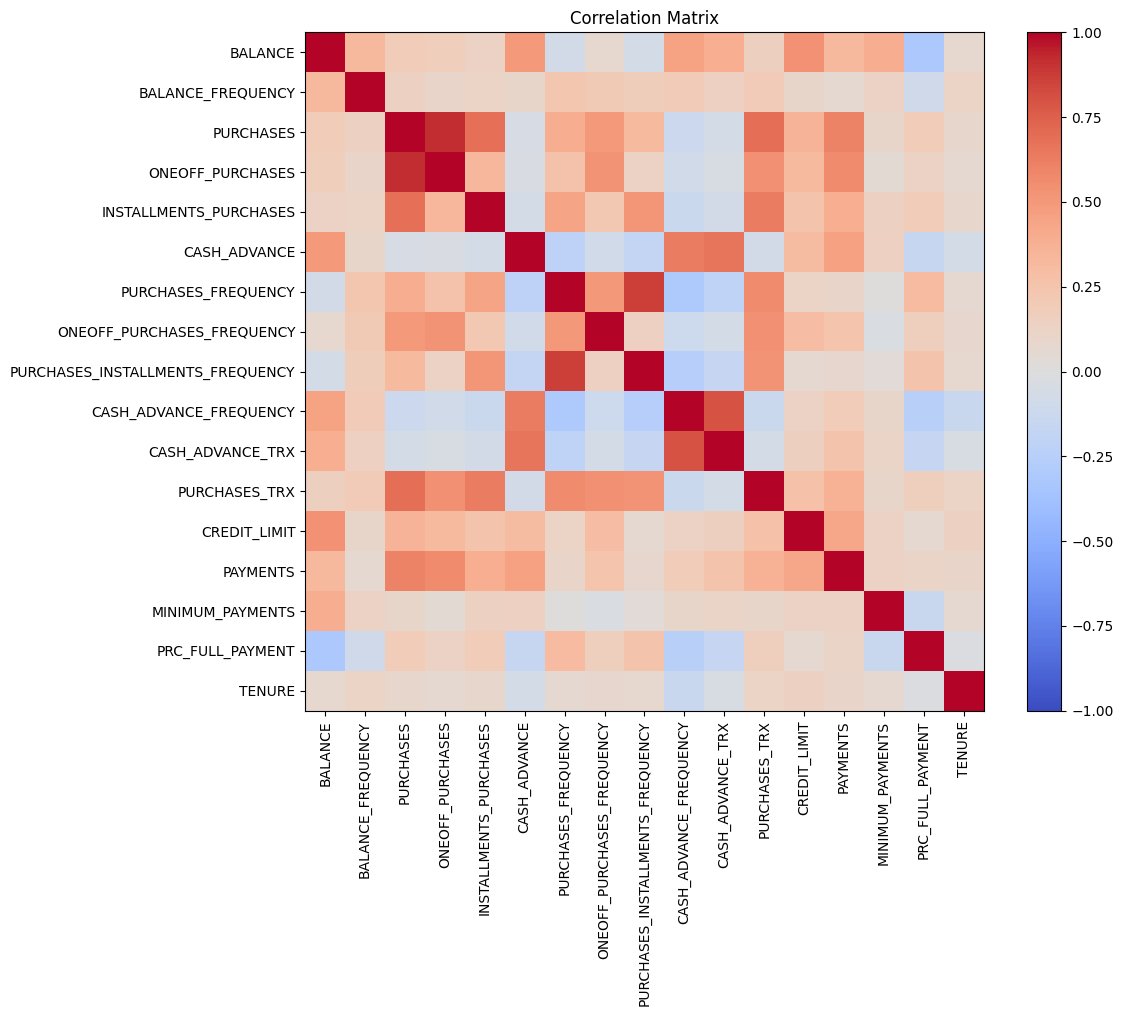

In [8]:
# Plot the correlation matrix

plt.figure(figsize=(12, 10))
corr = df.corr()
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [9]:
# Identify and remove redundant features. use 0.8 threshold.

threshold = 0.8
corr_matrix = df.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [col for col in upper.columns if any(upper[col] > threshold)]
print("Redundant features removed:", to_drop)

df = df.drop(columns=to_drop)

Redundant features removed: ['ONEOFF_PURCHASES', 'PURCHASES_INSTALLMENTS_FREQUENCY']


## Standardize the Data (5 points)
Standardize the dataset using z-score normalization

In [10]:
# todo

df_scaled = (df - df.mean()) / df.std()
df_scaled.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-0.731948,-0.249421,-0.424876,-0.349059,-0.466759,-0.806445,-0.678623,-0.675311,-0.476043,-0.511305,-0.960325,-0.528949,-0.302383,-0.525522,0.360659
1,0.786917,0.134317,-0.469526,-0.454551,2.605459,-1.221690,-0.678623,0.573931,0.110068,-0.591763,0.688640,0.818596,0.097494,0.234214,0.360659
2,0.447110,0.518055,-0.107662,-0.454551,-0.466759,1.269772,2.673302,-0.675311,-0.476043,-0.109014,0.826054,-0.383783,-0.093288,-0.525522,0.360659
3,0.049096,-1.016896,0.232045,-0.454551,-0.368633,-1.014069,-0.399297,-0.258899,-0.329515,-0.551534,0.826054,-0.598655,-0.228294,-0.525522,0.360659
4,-0.358755,0.518055,-0.462037,-0.454551,-0.466759,-1.014069,-0.399297,-0.675311,-0.476043,-0.551534,-0.905359,-0.364347,-0.257252,-0.525522,0.360659


Why is it important to standardize the data before applying PCA?
<br>
Answer:

PCA finds directions of maximum variance, and it's sensitive to the scale of each feature. Columns like CREDIT_LIMIT (thousands) and PRC_FULL_PAYMENT (0-1) have very different ranges, so without standardization PCA would be dominated by high-magnitude features like balance and credit limit, not because they're more important, but simply because their variance is numerically larger.

What is differnce between Normalizer and StandardScaler classes. which is better for PCA?
<br>
Answer:

StandardScaler rescales each feature (column) to have mean 0 and std 1, independently across samples.

Normalizer rescales each sample (row) to have unit norm independently across features.

StandardScaler is the right choice for PCA. PCA operates on the covariance structure between features, so features need to be on comparable scales. Normalizer instead changes the relationship between rows and would distort the feature covariance structure PCA depends on.

## Principal Component Analysis (PCA) (35 points)
Implement PCA from scratch.

In [11]:
import numpy as np

class CustomPCA:
    def __init__(self, n_components=None):
        """
        Initialize the PCA class with the number of components to keep.
        n_components: Number of principal components to keep. If None, all components are kept.
        """
        self.n_components = n_components
        self.components = None  # To store the principal components (eigenvectors)
        self.mean = None        # To store the mean of the data (used for centering the data)
        self.explained_variance_ratio = None  # To store the explained variance ratio of the components

    def fit(self, X):
        """
        Fit the PCA model on the dataset X by calculating the eigenvalues and eigenvectors of the covariance matrix.
        X: Input data (n_samples, n_features)
        """
        X = np.array(X)
        n_samples, n_features = X.shape

        self.mean = np.mean(X, axis=0)
        X_centered = X - self.mean

        cov_matrix = np.cov(X_centered, rowvar=False)

        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        sorted_idx = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_idx]
        eigenvectors = eigenvectors[:, sorted_idx]

        n_components = self.n_components if self.n_components is not None else n_features
        self.components = eigenvectors[:, :n_components]  

        total_variance = np.sum(eigenvalues)
        self.explained_variance_ratio = eigenvalues[:n_components] / total_variance

        return self


    def transform(self, X):
        """
        Transform the input data X into the new space using the principal components.
        X: Input data (n_samples, n_features)
        """
        # Return the transformed data
        X = np.array(X)
        X_centered = X - self.mean
        return X_centered @ self.components

    def get_explained_variance_ratio(self):
        """
        Return the explained variance ratio of each principal component.
        """
        return self.explained_variance_ratio

    def get_components(self):
        """
        Return the principal components (eigenvectors).
        """
        return self.components

### Visualizing the Cumulative Variance

Plot the cumulative explained variance to visualize the selection of components.  How many components are needed to explain 75% of the variance?
<br>
answer: 6 components are needed.

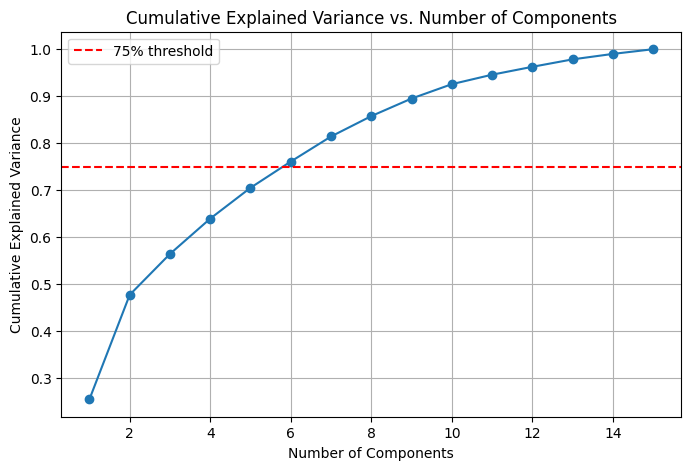

Number of components needed to explain 75% of variance: 6


In [12]:
# todo

pca_full = CustomPCA(n_components=None)
pca_full.fit(df_scaled)

explained_var_ratio = pca_full.get_explained_variance_ratio()
cumulative_var = np.cumsum(explained_var_ratio)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_var) + 1), cumulative_var, marker='o')
plt.axhline(y=0.75, color='r', linestyle='--', label='75% threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance vs. Number of Components')
plt.legend()
plt.grid(True)
plt.show()

n_components_75 = np.argmax(cumulative_var >= 0.75) + 1
print(f"Number of components needed to explain 75% of variance: {n_components_75}")

Build a new DataFrame with the first slected components. save it to a new CSV file named 'pca_output.csv'

In [13]:
#Build a new DataFrame with the first slected components

pca_selected = CustomPCA(n_components=n_components_75)
pca_selected.fit(df_scaled)
X_pca = pca_selected.transform(df_scaled)

pca_columns = [f'PC{i+1}' for i in range(n_components_75)]
df_pca = pd.DataFrame(X_pca, columns=pca_columns)

df_pca.to_csv('pca_output.csv', index=False)
df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6
0,1.731145,0.824038,-0.384299,-0.451598,-0.087761,0.438033
1,0.301381,-2.533496,0.621547,-0.939261,-0.794412,0.060612
2,-1.194132,0.887519,-1.184389,1.129052,-1.152561,-1.868925
3,0.930088,0.030104,-0.111207,-1.309379,-0.505424,-0.834621
4,1.499427,0.517751,-0.794256,-0.125369,-0.253035,0.326980


We expect these new features to be orthogonal to each other. Check this and show the correlation between the features.

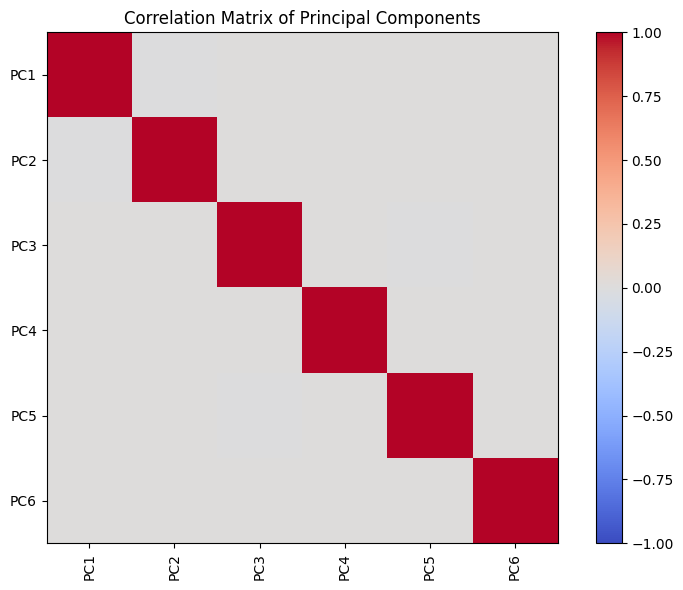

In [14]:
# todo

pca_corr = df_pca.corr()

plt.figure(figsize=(8, 6))
plt.imshow(pca_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(pca_corr.columns)), pca_corr.columns, rotation=90)
plt.yticks(range(len(pca_corr.columns)), pca_corr.columns)
plt.title('Correlation Matrix of Principal Components')
plt.tight_layout()
plt.show()

## KMeans (45 points)
Implement kmeans from scratch.

In [15]:
import numpy as np

class CustomKMeans:
    def __init__(self, n_clusters=3, max_iter=100, random_state=42):
        """
        Initialize the KMeans class with the number of clusters and maximum iterations.
        n_clusters: Number of clusters to form.
        max_iter: Maximum number of iterations for convergence.
        random_state: Seed for reproducibility.
        """
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.centroids = None  # To store the centroids of clusters
        self.inertia_ = None   # To store the inertia (within-cluster sum of squares)
        self.labels_ = None    # To store the label assigned to each data point (cluster assignment)

    def fit(self, X):
        """
        Fit the KMeans model on the dataset X.
        X: Input data (n_samples, n_features)
        """
        X = np.array(X)
        n_samples, n_features = X.shape
        rng = np.random.RandomState(self.random_state)

        init_idx = rng.choice(n_samples, self.n_clusters, replace=False)
        self.centroids = X[init_idx].copy()

        for _ in range(self.max_iter):

            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2) 
            labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            for k in range(self.n_clusters):
                points_in_cluster = X[labels == k]
                if len(points_in_cluster) > 0:
                    new_centroids[k] = points_in_cluster.mean(axis=0)
                else:
                    new_centroids[k] = self.centroids[k]

            if np.allclose(new_centroids, self.centroids):
                self.centroids = new_centroids
                self.labels_ = labels
                break

            self.centroids = new_centroids
            self.labels_ = labels

        self.inertia_ = self._calculate_inertia(X)
        return self

    def _calculate_inertia(self, X):
        """
        Calculate the within-cluster sum of squared distances (inertia).
        X: Input data (n_samples, n_features)
        Returns: inertia (float)
        """
        # Step 1: For each cluster, compute the squared distances of points from their corresponding centroid
        # Step 2: Sum all squared distances to compute inertia
        inertia = 0.0
        for k in range(self.n_clusters):
            points_in_cluster = X[self.labels_ == k]
            if len(points_in_cluster) > 0:
                inertia += np.sum((points_in_cluster - self.centroids[k]) ** 2)
        return inertia

### Elbow Method
Apply the elbow method to determine the optimal number of clusters for K-Means. what is the best number of clusters? 9 clusters.

In [16]:
# Initialize an empty list to store the WCSS values for each number of clusters
WCSS = []

# Apply KMeans for a range of cluster values (from 1 to 30)
for i in range(1, 30):
    # Initialize the CustomKMeans with `i` clusters and a random state of 42
    kmeans_pca = CustomKMeans(n_clusters=i, random_state=42)
    
    # Fit the model to the PCA-transformed data
    kmeans_pca.fit(df_pca)

    # Append the calculated inertia (WCSS) to the WCSS list
    WCSS.append(kmeans_pca.inertia_)

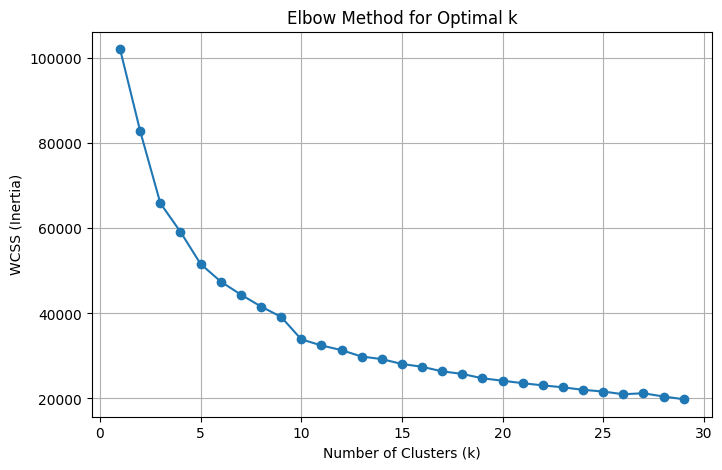

In [17]:
# Plot the Elbow curve using Matplotlib
plt.figure(figsize=(8, 5))
plt.plot(range(1, 30), WCSS, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()


Apply the optimal KMeans clustering on the PCA-transformed data, and assign cluster labels to each observation. Add a new column named segment to the df_pca DataFrame to store these labels.

In [22]:
# Apply KMeans on PCA-reduced data with the optimal number of clusters based on the elbow method
optimal_k = 9

kmeans_optimal = CustomKMeans(n_clusters=optimal_k, random_state=42)
kmeans_optimal.fit(df_pca)


In [23]:
# Add a new column 'segment' to pca data frame and assign the cluster labels to each observation
df_pca['segment'] = kmeans_optimal.labels_
df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,segment
0,1.731145,0.824038,-0.384299,-0.451598,-0.087761,0.438033,5
1,0.301381,-2.533496,0.621547,-0.939261,-0.794412,0.060612,6
2,-1.194132,0.887519,-1.184389,1.129052,-1.152561,-1.868925,8
3,0.930088,0.030104,-0.111207,-1.309379,-0.505424,-0.834621,5
4,1.499427,0.517751,-0.794256,-0.125369,-0.253035,0.326980,5


 visualize the clustering by plotting the pairwise relationships of the PCA-reduced features, color-coded by the cluster assignments.

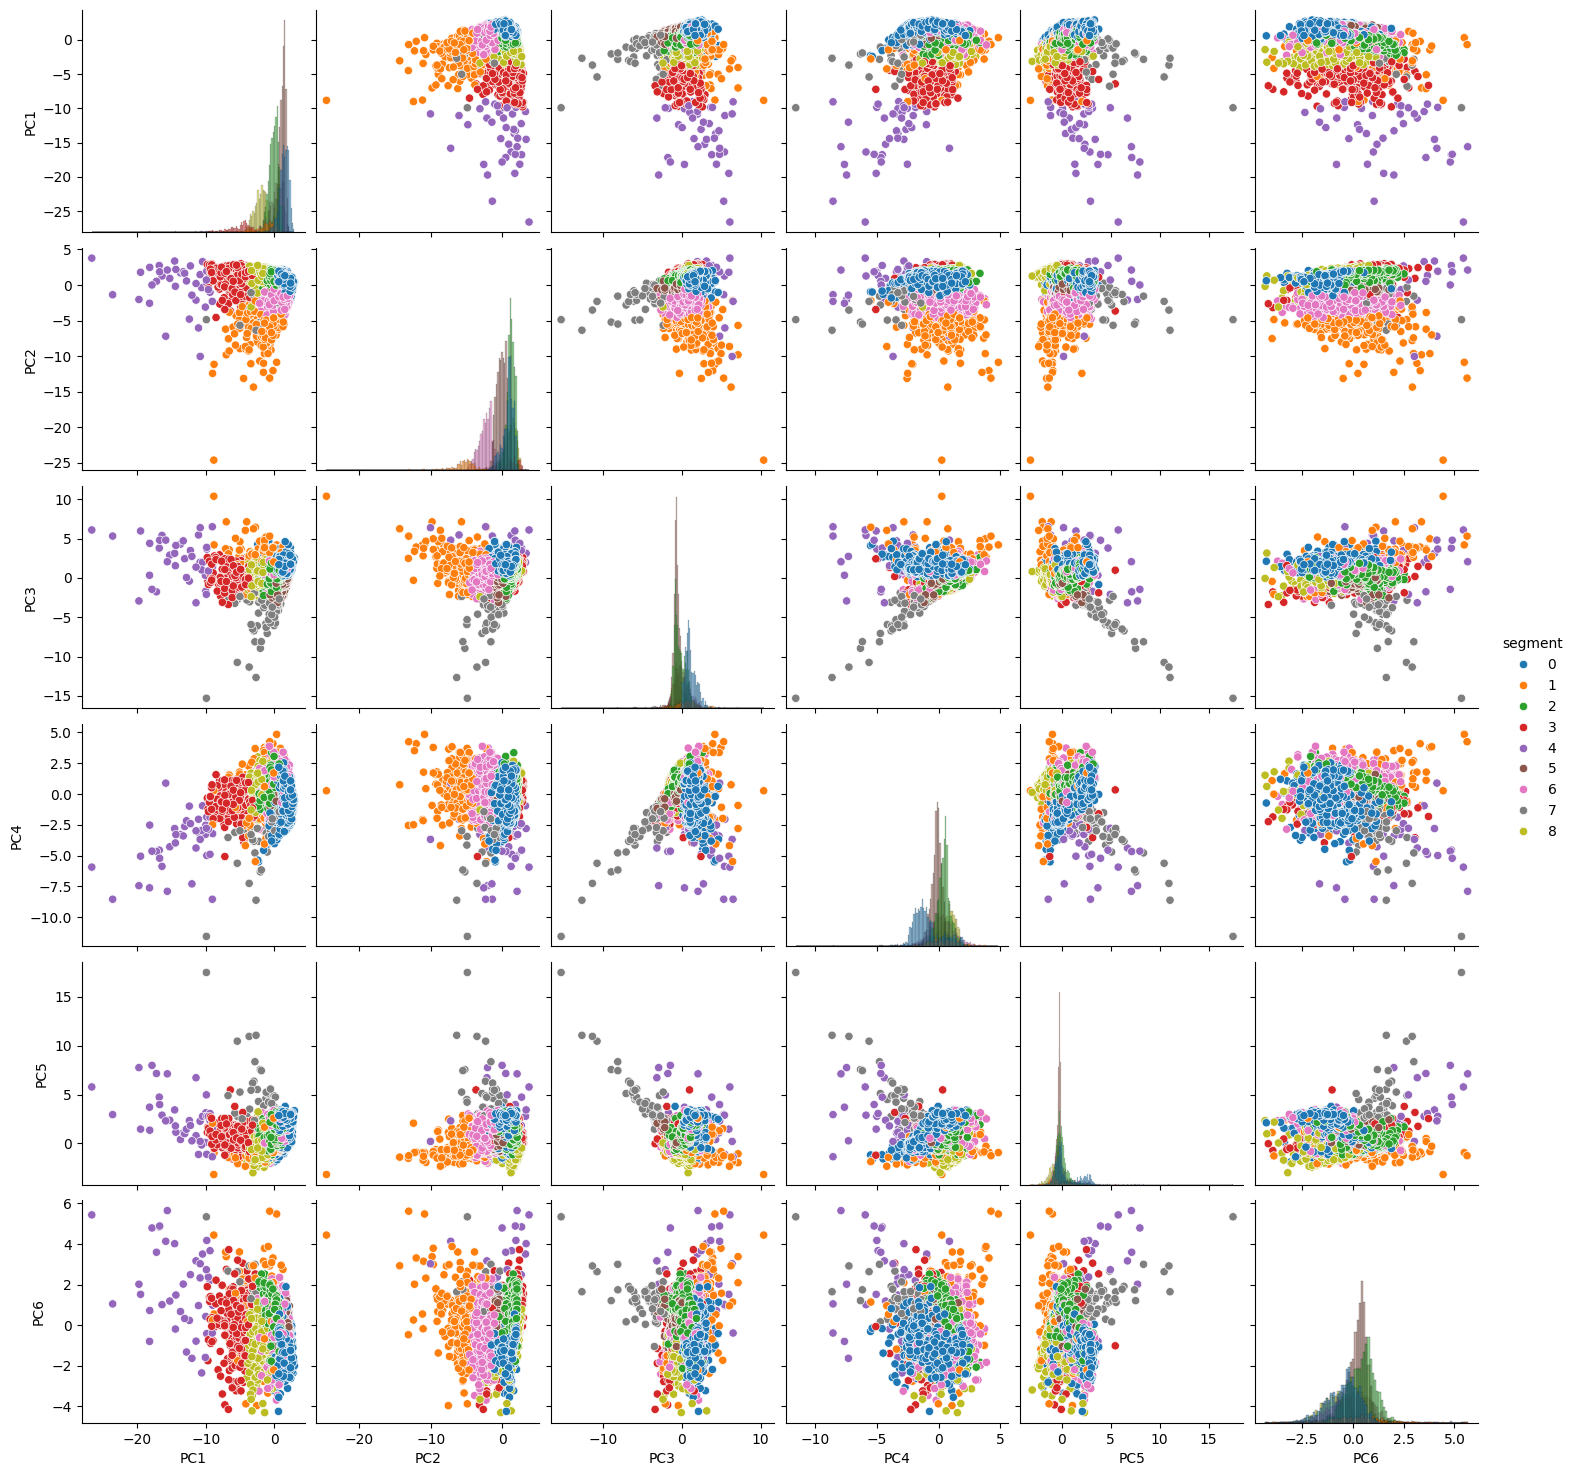

In [24]:
# todo

pca_feature_cols = [col for col in df_pca.columns if col != 'segment']
sns.pairplot(df_pca, vars=pca_feature_cols, hue='segment', palette='tab10', diag_kind='hist')
plt.show()

So, when we employ PCA prior to using K-means we can visually separate almost the entire data set. That was one of the biggest goals of PCA - to reduce the number of variables by combining them into bigger, more meaningful features.

### Hierarchical Clustering
Perform hierarchical clustering on the reduced dataset after PCA. Use complete linkage method.


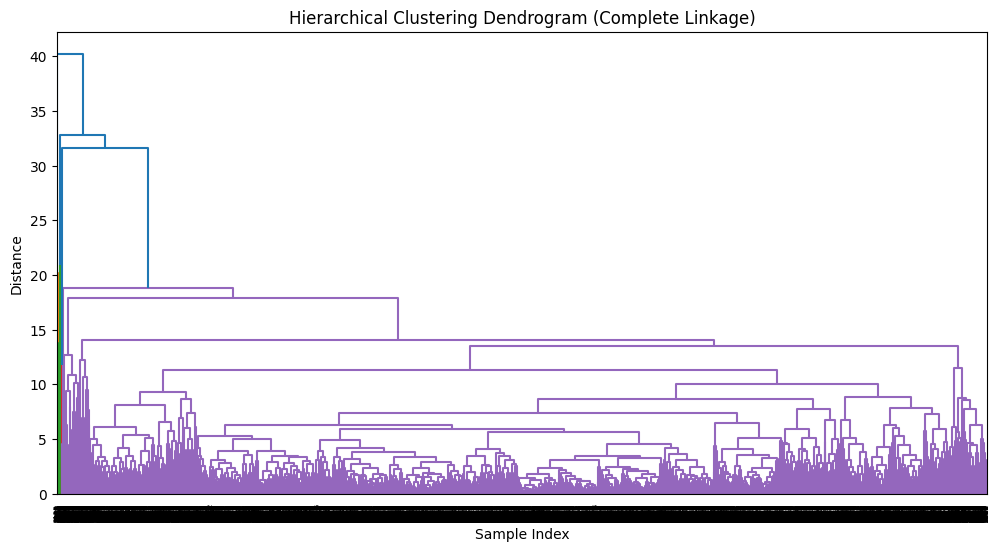

In [25]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Perform Hierarchical Clustering on the pca dataset
pca_features = df_pca.drop(columns=['segment'])
Z = linkage(pca_features, method='complete')

# Visualize the dendrogram
plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.title('Hierarchical Clustering Dendrogram (Complete Linkage)')
plt.show()

"Use scipy.cluster.hierarchy.fcluster to assign clusters from the dendrogram with a specified number of 5 clusters. Then visualize the results using pairplots.

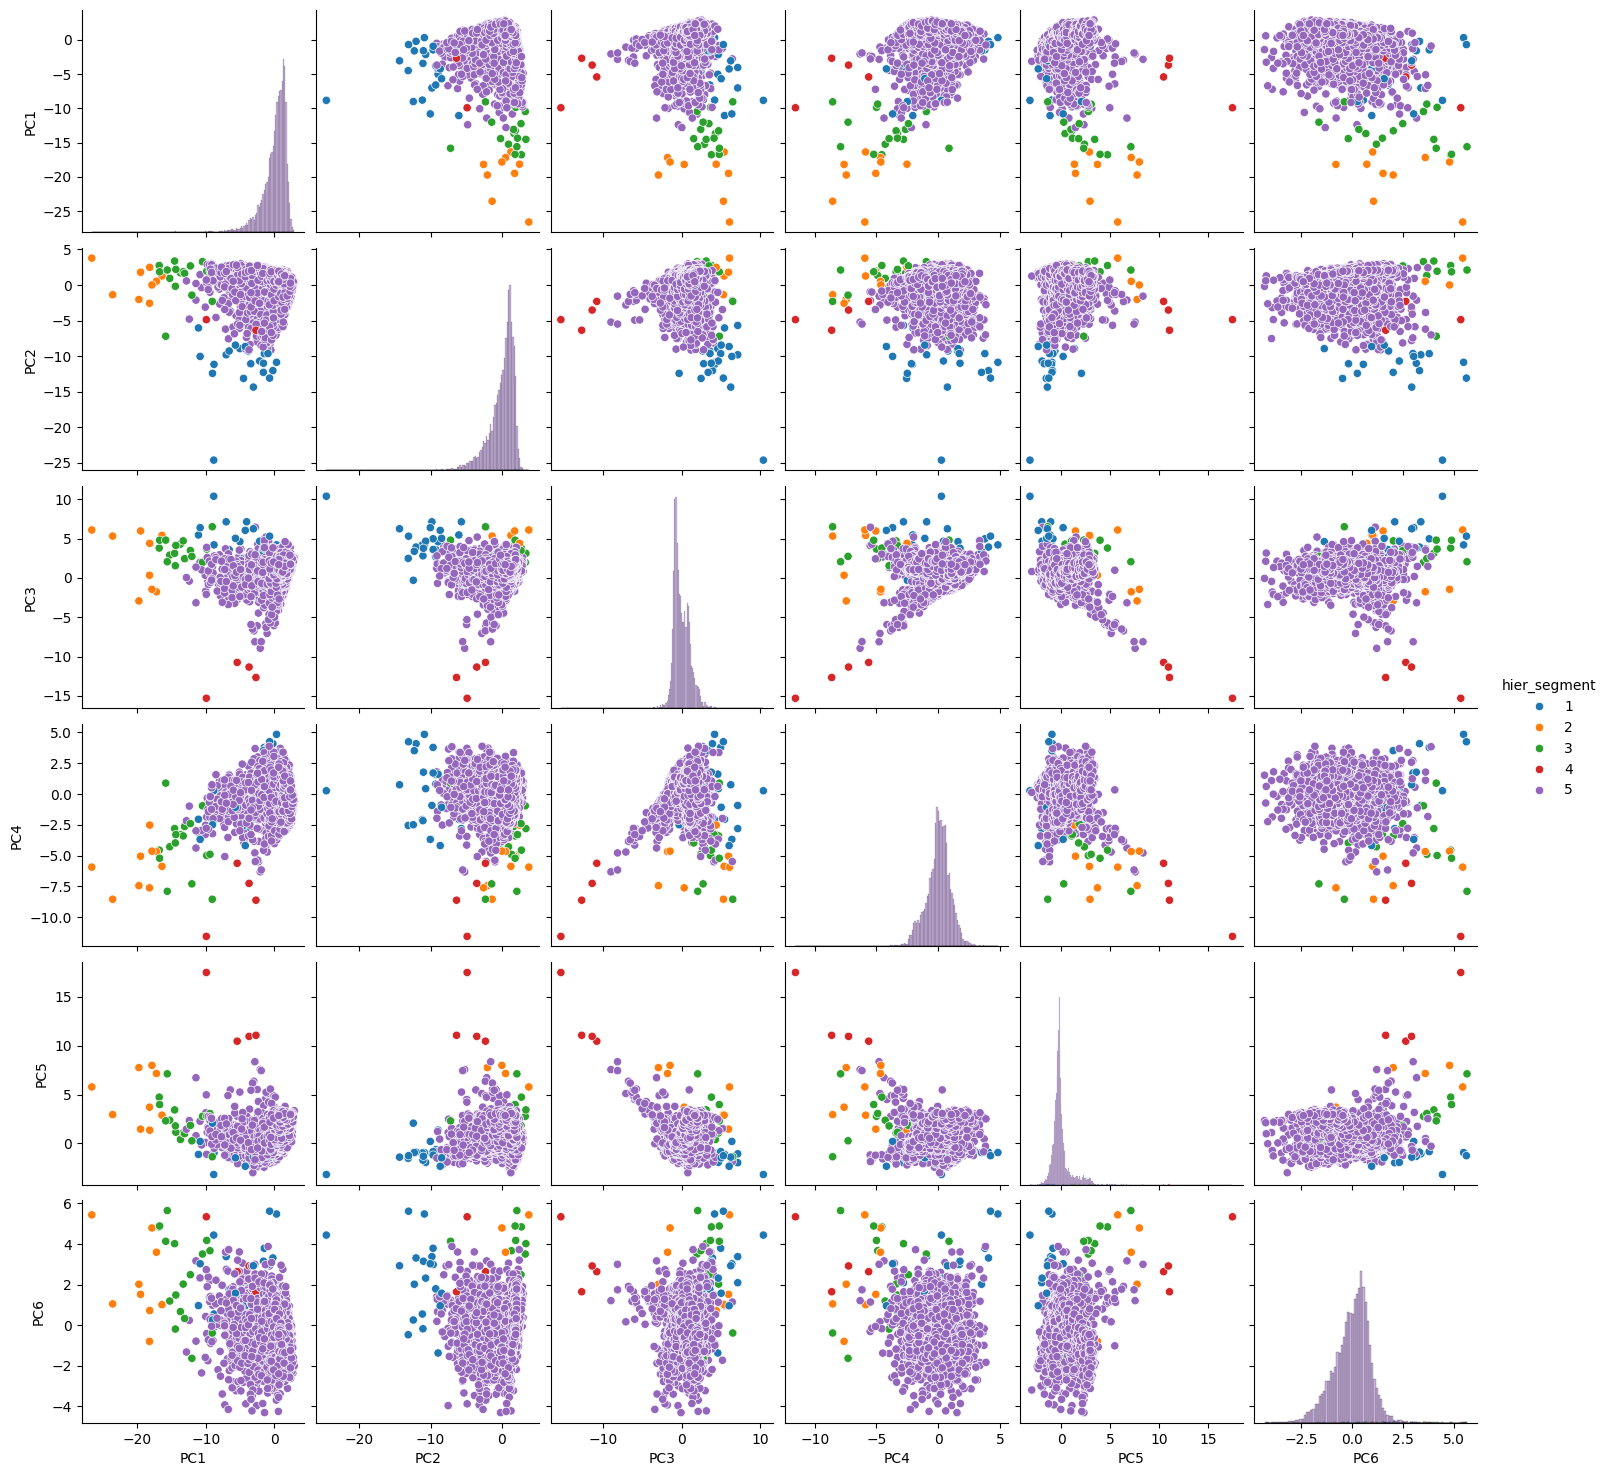

In [26]:
from scipy.cluster.hierarchy import fcluster

# Choose threshold and assign clusters
hier_labels = fcluster(Z, t=5, criterion='maxclust')

# Assign cluster labels to PCA DataFrame
df_pca['hier_segment'] = hier_labels

# Visualize using PCA components
pca_feature_cols = [col for col in df_pca.columns if col not in ['segment', 'hier_segment']]
sns.pairplot(df_pca, vars=pca_feature_cols, hue='hier_segment', palette='tab10', diag_kind='hist')
plt.show()